<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Cloud-Native Rasters: COG, Zarr and STAC

Notebook 08_00 showed that a cloud-optimized file lets a program read a small part of a large
remote raster. This notebook is about producing and managing such files. We download Sentinel-2
imagery of Syracuse with `geolattice.rsense.get_images`, check whether the files are cloud-optimized,
convert them to Cloud-Optimized GeoTIFFs (COGs) and compare compression settings, look inside a
COG, build a multi-date **Zarr** data cube, and publish the products in a **STAC** catalogue
whose footprints are also stored as GeoParquet.



### Learning objectives

1. Download clipped imagery with `get_images` and read its STAC metadata (scale and offset).
2. Check files with `validate_cog` and explain each rule of the COG layout.
3. Convert rasters with `to_cog` and choose compression, predictor and block size.
4. Make a web-optimized COG aligned with the XYZ tile grid.
5. Confirm that a clip read from the cloud is identical to the remote file.
6. Build, append to and lazily read a Zarr data cube.
7. Publish products as a STAC catalogue and index its footprints in GeoParquet.



### Data

| Data | Source |
|---|---|
| Sentinel-2 L2A, tile 18TVN, red/green/blue/NIR (10 m) and scene classification (20 m), clearest scene of July, August and September 2025 over Syracuse, NY | Downloaded with `get_images` from Earth Search (AWS) into `Data/00_shared/data_web_cloud_gis/s2_syracuse_2025/` |
| Onondaga County boundary | `Data/00_shared/vector_data/USA/NY_County_GCS.shp` |



### Contents

1. Setup
2. Getting imagery with `get_images`
3. Is it cloud-optimized?
4. Converting to COG and choosing compression
5. Inside a COG
6. Web-optimized COGs
7. Local copy versus the cloud original
8. From files to a data cube: scale, offset and cloud masks
9. Zarr data cubes
10. Publishing with STAC and GeoParquet
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: imports, paths, and the Syracuse AOI for this COG / Zarr notebook
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import json
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

import geolattice
import geolattice.rsense as rs
import geolattice.web as web
from geolattice.rsense.get_images import get_images, search_images
from geolattice.vector import read_geoparquet, write_geoparquet

# Quiet GDAL logs and prepare shared working directories
rasterio.Env(CPL_LOG="/dev/null").__enter__()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
DATA = Path("../../../Data")
WORK = DATA / "00_shared" / "data_web_cloud_gis"                     # downloads, shared with later notebooks
OUT = WORK / "08_01_outputs"                           # products written by this notebook
OUT.mkdir(parents=True, exist_ok=True)
AOI = (-76.22, 42.98, -76.04, 43.10)                   # downtown Syracuse and the south end of Onondaga Lake
print("geolattice", geolattice.__version__, "| rsense", rs.__version__, "| outputs:", OUT)


geolattice 0.3.11 | rsense 0.2.0.dev0 | outputs: ../../../data/data_web_cloud_gis/08_01_outputs


## Getting imagery with `get_images`

We want the clearest Sentinel-2 scene of each summer month. `search_images` lists candidates
without downloading; we keep scenes from MGRS tile **18TVN**, which covers the whole area, so all
dates share one pixel grid, and pick the least cloudy scene per month. `get_images(search=...,
ids=...)` then downloads only those scenes, clipped to the area (`mode="clip"`, the default),
with the red, green, blue, NIR and scene-classification (`scl`) bands and an RGB+NIR `stack.tif`.

The download runs once; later runs (and later notebooks) reuse the folder.

In [2]:
# Search for clear Sentinel-2 scenes on tile 18TVN and download if needed
S2_DIR = WORK / "s2_syracuse_2025"
found = search_images(bbox=AOI, dates=("2025-06-01", "2025-09-30"), source="earth-search",
                      collection="sentinel-2-l2a", cloud=20, limit=500, quiet=True)
cands = pd.DataFrame(found.scenes)
cands["date"] = pd.to_datetime(cands["datetime"])
cands = cands[cands["id"].str.contains("18TVN")]
best = cands.sort_values("cloud").groupby(cands["date"].dt.month).head(1).sort_values("date")
print(f"{len(found.scenes)} scenes ≤ 20 % cloud, {len(cands)} on tile 18TVN; clearest per month:")
display(best[["id", "date", "cloud"]].assign(cloud=lambda d: d.cloud.round(2)))

# Download stacked RGB+NIR+SCL bands once; reuse if already on disk
if not (S2_DIR / "request.json").exists() or any(not (S2_DIR / sid).exists() for sid in best["id"]):
    t0 = time.perf_counter()
    result = get_images(S2_DIR, search=found, ids=list(best["id"]),
                        bands=["red", "green", "blue", "nir", "scl"], stack=True, quiet=True)
    print(result, f"in {time.perf_counter() - t0:.0f} s")
else:
    print("Already downloaded:", S2_DIR)
files = sorted(p.relative_to(S2_DIR) for p in S2_DIR.rglob("*") if p.is_file())
print(f"{len(files)} files, {sum((S2_DIR / f).stat().st_size for f in files) / 1e6:.1f} MB:")
print("\n".join("  " + str(f) for f in files))


31 scenes ≤ 20 % cloud, 15 on tile 18TVN; clearest per month:


,id,date,cloud
4,S2C_18TVN_20250723_0_L2A,2025-07-23 16:01:45.187000+00:00,13.99
9,S2C_18TVN_20250802_0_L2A,2025-08-02 16:01:42.845000+00:00,0.17
30,S2B_18TVN_20250919_0_L2A,2025-09-19 16:11:16.421000+00:00,2.23


Already downloaded: ../../../data/data_web_cloud_gis/s2_syracuse_2025
24 files, 72.2 MB:
  S2B_18TVN_20250919_0_L2A/blue.tif
  S2B_18TVN_20250919_0_L2A/green.tif
  S2B_18TVN_20250919_0_L2A/item.json
  S2B_18TVN_20250919_0_L2A/nir.tif
  S2B_18TVN_20250919_0_L2A/red.tif
  S2B_18TVN_20250919_0_L2A/scl.tif
  S2B_18TVN_20250919_0_L2A/stack.tif
  S2C_18TVN_20250723_0_L2A/blue.tif
  S2C_18TVN_20250723_0_L2A/green.tif
  S2C_18TVN_20250723_0_L2A/item.json
  S2C_18TVN_20250723_0_L2A/nir.tif
  S2C_18TVN_20250723_0_L2A/red.tif
  S2C_18TVN_20250723_0_L2A/scl.tif
  S2C_18TVN_20250723_0_L2A/stack.tif
  S2C_18TVN_20250802_0_L2A/blue.tif
  S2C_18TVN_20250802_0_L2A/green.tif
  S2C_18TVN_20250802_0_L2A/item.json
  S2C_18TVN_20250802_0_L2A/nir.tif
  S2C_18TVN_20250802_0_L2A/red.tif
  S2C_18TVN_20250802_0_L2A/scl.tif
  S2C_18TVN_20250802_0_L2A/stack.tif
  aoi.geojson
  request.json
  scenes.json


`get_images` records the request (`request.json`), the area (`aoi.geojson`) and, for each scene,
its full STAC item (`item.json`). The item is the scene's metadata: acquisition time, processing
baseline, and for each band its data type, no-data value and the **scale and offset** that turn
stored integers into reflectance.

In [3]:
# Inspect STAC item properties and per-band raster metadata for the first scene
SCENES = list(best["id"])
item = json.loads((S2_DIR / SCENES[0] / "item.json").read_text())
props = item["properties"]
print({k: props.get(k) for k in ["datetime", "platform", "eo:cloud_cover", "s2:processing_baseline", "proj:code",
                                  "earthsearch:boa_offset_applied"] if props.get(k) is not None})
pd.DataFrame({band: item["assets"][band]["raster:bands"][0] for band in ["red", "green", "blue", "nir", "scl"]}).T


{'datetime': '2025-07-23T16:01:45.187000Z', 'platform': 'sentinel-2c', 'eo:cloud_cover': 13.994041, 's2:processing_baseline': '05.11', 'proj:code': 'EPSG:32618', 'earthsearch:boa_offset_applied': True}


,nodata,data_type,spatial_resolution,scale,offset
red,0,uint16,10,0.0001,-0.1
green,0,uint16,10,0.0001,-0.1
blue,0,uint16,10,0.0001,-0.1
nir,0,uint16,10,0.0001,-0.1
scl,0,uint8,20,NaN,NaN


## Is it cloud-optimized?

`validate_cog` checks the layout rules of a COG:

1. **tiled** pixels (square blocks, not full-width strips);
2. **internal overviews** for images larger than about 512 pixels;
3. **headers first**: the image file directories (IFDs) at the start, full resolution then overviews;
4. **data ordered** from the smallest overview to full resolution, after all headers.

Missing overviews and a missing `LAYOUT=COG` marker are warnings; `strict=True` treats them as errors.

In [4]:
# Validate that the local multi-band stack is a Cloud Optimized GeoTIFF
stack_path = S2_DIR / SCENES[0] / "stack.tif"
report = web.validate_cog(stack_path)
print(report)
pd.Series({k: report.details[k] for k in ["size", "bands", "dtype", "block_size", "overview_count", "compression", "layout"]}).to_frame("value")


../../../data/data_web_cloud_gis/s2_syracuse_2025/S2C_18TVN_20250723_0_L2A/stack.tif: NOT a valid Cloud-Optimized GeoTIFF
  error: Some pixel data come before the image file directories.


,value
size,"(1485, 1354)"
bands,4
dtype,UInt16
block_size,"(256, 256)"
overview_count,0
compression,DEFLATE
layout,None


In [5]:
# Strict COG check on the local stack, then validate the remote red band
print("strict check:", web.validate_cog(stack_path, strict=True).valid)
remote = item["assets"]["red"]["href"]
with web.cloud_env(anonymous=True):
    original = web.validate_cog(remote)
print("The cloud original:", original.valid, {k: original.details[k] for k in ["size", "block_size", "overview_count", "compression", "layout"]})


strict check: False


The cloud original: True {'size': (10980, 10980), 'block_size': (1024, 1024), 'overview_count': 4, 'compression': 'DEFLATE', 'layout': 'COG'}


The file `get_images` wrote is a tiled (256 × 256), DEFLATE-compressed GeoTIFF, which is fine for
local work, but it is **not** a COG. It has no overviews, and GDAL's ordinary GeoTIFF writer put
the pixel data before the image file directories, so a remote reader would have to look for the
headers. The source it was clipped from, the Sentinel-2 band on AWS, is a valid COG: 1,024-pixel
blocks, four overviews and the `LAYOUT=COG` marker. Clipping keeps the pixels but not the layout,
which is why outputs should be converted before they are published.



## Converting to COG and choosing compression

`to_cog` uses GDAL's COG driver, which tiles the image, builds internal overviews and writes the
parts in the right order. The main choices are compression and, for integer data, the
**predictor**: predictor 2 stores the difference between neighbouring pixels, which are small
for smooth imagery and compress better. All the options below are lossless.

In [6]:
# Rewrite the stack as COGs under several compression options and compare size/speed
options = {
    "none":               dict(compress="NONE"),
    "LZW":                dict(compress="LZW"),
    "DEFLATE":            dict(compress="DEFLATE"),
    "DEFLATE + predictor": dict(compress="DEFLATE", predictor=2),
    "ZSTD + predictor":   dict(compress="ZSTD", predictor=2),
    "ZSTD level 15 + predictor": dict(compress="ZSTD", predictor=2, level=15),
}
# Uncompressed reference array for lossless checks
with rasterio.open(stack_path) as src:
    reference = src.read()
rows = []
# Write each variant, time readback, and record COG details
for name, opts in options.items():
    dst = OUT / f"stack_{name.split()[0].lower()}_{len(opts)}.tif"
    t0 = time.perf_counter(); web.to_cog(stack_path, dst, blocksize=512, **opts); t_write = time.perf_counter() - t0
    t0 = time.perf_counter()
    with rasterio.open(dst) as src:
        back = src.read()
    t_read = time.perf_counter() - t0
    rep = web.validate_cog(dst, strict=True)
    rows.append({"option": name, "MB": dst.stat().st_size / 1e6, "write s": t_write, "read s": t_read,
                 "lossless": bool(np.array_equal(back, reference)), "strict COG": rep.valid,
                 "overviews": rep.details["overview_count"]})
comp = pd.DataFrame(rows).set_index("option")
comp["vs. input"] = (comp["MB"] / (stack_path.stat().st_size / 1e6)).round(2)
print(f"Input stack.tif: {stack_path.stat().st_size / 1e6:.1f} MB ({reference.nbytes / 1e6:.1f} MB uncompressed in memory)")
comp.round(3)


Input stack.tif: 12.2 MB (16.1 MB uncompressed in memory)


,MB,write s,read s,lossless,strict COG,overviews,vs. input
option,,,,,,,
none,29.362,0.128,0.006,True,False,2,2.41
LZW,21.749,0.217,0.067,True,True,2,1.78
DEFLATE,17.198,0.178,0.059,True,True,2,1.41
DEFLATE + predictor,15.928,0.181,0.062,True,True,2,1.31
ZSTD + predictor,14.888,0.235,0.030,True,True,2,1.22
ZSTD level 15 + predictor,14.864,0.647,0.031,True,True,2,1.22


Every option is lossless (the pixels read back unchanged) and, apart from the uncompressed file,
passes the strict COG check. Each file includes two overview levels, which is why even the
uncompressed COG (29.4 MB) is larger than the 16.1 MB of pixels.

* The predictor helps: DEFLATE goes from 17.2 to 15.9 MB with predictor 2.
* ZSTD with the predictor gave the smallest file (14.9 MB) and the fastest reads.
* A higher ZSTD level saved almost nothing (14.86 MB) and took nearly three times as long to write.

LZW, the old default, was the largest of the compressed files. A good general choice is ZSTD or
DEFLATE with a predictor at the default level.



## Inside a COG

The DEFLATE + predictor file is our working COG. Its byte offsets show the layout rules at work,
and its overviews are ready-made reduced copies.

,level,size (px),IFD offset (byte),first tile offset (byte)
0,full resolution,"(1485, 1354)",192,3888865
1,overview 1,"(742, 677)",1008,789653
2,overview 2,"(371, 338)",1228,1556


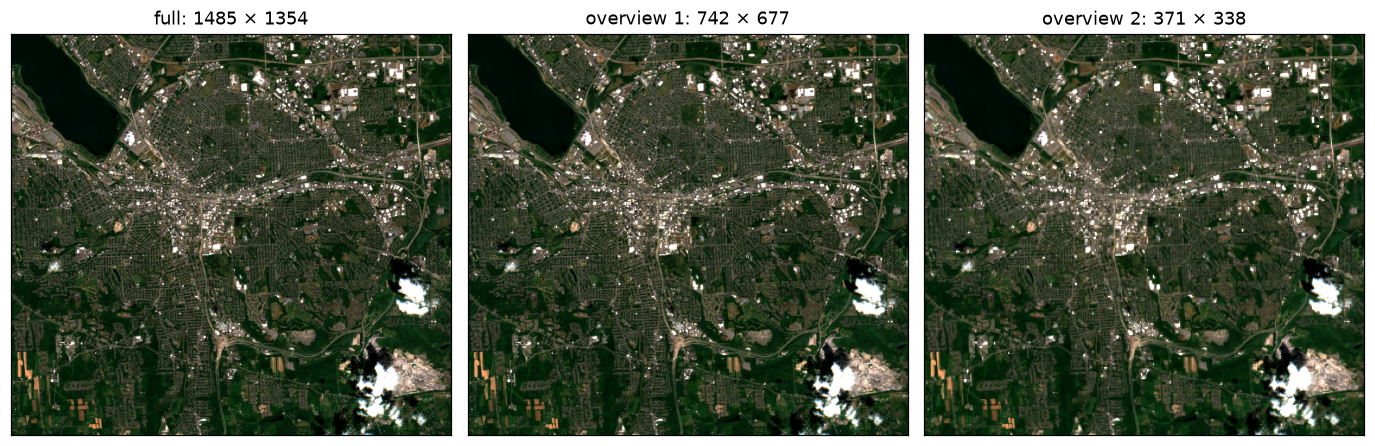

In [7]:
# Show COG overview layout and visualize RGB at each resolution level
cog_path = OUT / "stack_deflate_2.tif"
rep = web.validate_cog(cog_path)
layout = pd.DataFrame({
    "level": ["full resolution"] + [f"overview {i + 1}" for i in range(rep.details["overview_count"])],
    "size (px)": [rep.details["size"]] + rep.details["overview_sizes"],
    "IFD offset (byte)": rep.details["ifd_offsets"],
    "first tile offset (byte)": rep.details["data_offsets"],
})
display(layout)

# Render full resolution plus each overview
with rasterio.open(cog_path) as src:
    levels = [None] + list(range(len(src.overviews(1))))
fig, axes = plt.subplots(1, len(levels), figsize=(4.2 * len(levels), 4))
for ax, lvl in zip(axes, levels):
    with rasterio.open(cog_path, overview_level=lvl) if lvl is not None else rasterio.open(cog_path) as src:
        rgb = src.read([1, 2, 3]).astype("float32")
    p2, p98 = np.percentile(rgb, [2, 98])
    ax.imshow(np.clip((np.moveaxis(rgb, 0, -1) - p2) / (p98 - p2), 0, 1))
    ax.set_title(f"{'full' if lvl is None else f'overview {lvl + 1}'}: {rgb.shape[2]} × {rgb.shape[1]}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


The offsets show the COG rules at work:

* **Headers first.** All three image file directories sit in the first 1.3 kB of the file (bytes
  192, 1,008 and 1,228), in order full resolution, overview 1, overview 2.
* **Coarse to fine.** The pixel data follow from coarsest to finest: overview 2 starts at byte
  1,556, overview 1 at 0.79 MB and full resolution at 3.9 MB.

A client that wants a small preview reads the first few kilobytes and stops. Each overview halves
the size (1,485 → 742 → 371 pixels), and the three images look alike at this display size, which
is exactly what makes zoomed-out views cheap.



## Web-optimized COGs

A web map asks for tiles in Web Mercator. If the COG is already in Web Mercator **and** its
blocks line up with the XYZ tile grid, a tile server can return blocks almost directly instead of
reprojecting. `to_cog(..., web_optimized=True)` produces such a file.

In [8]:
# Build a web-optimized COG aligned to the Web Mercator tile grid
web_cog = web.to_cog(cog_path, OUT / "stack_web_optimized.tif", web_optimized=True, predictor=2,
                     overview_resampling="AVERAGE", resampling="BILINEAR")
with rasterio.open(web_cog) as src:
    res = src.res[0]
    t = src.transform
    zoom = int(round(np.log2(2 * web.tiles.ORIGIN_SHIFT / (256 * res))))
    tile_span = 256 * res
    aligned = all(abs(((v + web.tiles.ORIGIN_SHIFT) / tile_span) - round((v + web.tiles.ORIGIN_SHIFT) / tile_span)) < 1e-6
                  for v in (t.c, web.tiles.ORIGIN_SHIFT - t.f))
    print(f"CRS {src.crs}, pixel {res:.3f} m (zoom {zoom}: {web.tile_resolution(zoom):.3f} m), "
          f"blocks {src.block_shapes[0]}, size {src.width} × {src.height}, {Path(web_cog).stat().st_size / 1e6:.1f} MB")
    print(f"Upper-left corner on the zoom-{zoom} tile grid: {aligned}")
print(web.validate_cog(web_cog, strict=True))


CRS EPSG:3857, pixel 19.109 m (zoom 13: 19.109 m), blocks (512, 512), size 1536 × 1536, 8.3 MB
Upper-left corner on the zoom-13 tile grid: True
../../../data/data_web_cloud_gis/08_01_outputs/stack_web_optimized.tif: valid Cloud-Optimized GeoTIFF


The web-optimized copy is in Web Mercator at 19.109 m per pixel, exactly the pixel size of XYZ
zoom 13. Its corner falls on the zoom-13 tile grid, and its 512-pixel blocks are whole multiples of
256-pixel tiles, so map tiles at zoom 13 and below line up with blocks and overviews.

Two costs: the image was resampled from 10 m to 19 m (GDAL picks the nearest zoom level at or
below the native resolution), and in Web Mercator the pixels are not equal-area. Keep the UTM
COG for analysis and the web-optimized copy for display.



## Local copy versus the cloud original

`get_images` reads the area out of each remote COG with range requests. Reading the same window
again straight from the cloud should give identical pixels.

In [9]:
# Compare a local red band to the same window read from the remote COG
local = rs.read(S2_DIR / SCENES[1] / "red.tif").squeeze("band", drop=True)
item1 = json.loads((S2_DIR / SCENES[1] / "item.json").read_text())
t0 = time.perf_counter()
with web.cloud_env(anonymous=True):
    remote_red = rs.read(item1["assets"]["red"]["href"], chunks={"x": 1024, "y": 1024}) \
        .squeeze("band", drop=True).rio.clip_box(*local.rio.bounds()).compute()
elapsed = time.perf_counter() - t0
same_grid = remote_red.shape == local.shape and np.allclose(remote_red.x, local.x) and np.allclose(remote_red.y, local.y)
print(f"Remote clip {remote_red.shape} read in {elapsed:.1f} s; same grid: {same_grid}; "
      f"identical values: {bool(np.array_equal(remote_red.values, local.values, equal_nan=True))}")


Remote clip (1354, 1485) read in 25.0 s; same grid: True; identical values: True


## From files to a data cube: scale, offset and cloud masks

The three dates share one grid, so they stack into a cube with dimensions (time, y, x). The STAC
item says reflectance = DN × `scale` + `offset`, with 0.0001 and −0.1. But read the metadata
carefully: since processing baseline 04.00 (January 2022) ESA adds 1,000 to every Sentinel-2 L2A
value, which the −0.1 offset removes, and Earth Search **already removed it** when it converted
the data to COGs. The item flags this with `earthsearch:boa_offset_applied: true`, while
`raster:bands` still lists the offset. Applying both would subtract it twice.

We can check this against Planetary Computer, which keeps ESA's original values, by reading the
same scene and window from both catalogues:

In [10]:
# Optional: compare Earth Search vs Planetary Computer DN values for the same scene
item_aug = json.loads((S2_DIR / SCENES[1] / "item.json").read_text())
es_red = rs.read(S2_DIR / SCENES[1] / "red.tif").squeeze("band", drop=True)
try:
    pc_items = rs.access.stac_search("sentinel-2-l2a", aoi=AOI, dates=(item_aug["properties"]["datetime"][:10],) * 2)
    pc_item = next(it for it in pc_items if "T18TVN" in it.id)
    pc_red = rs.read(pc_item.assets["B04"].href, chunks={"x": 1024, "y": 1024}).squeeze("band", drop=True) \
        .rio.clip_box(*es_red.rio.bounds()).compute()
    diff = (pc_red - es_red).values
    print(f"Planetary Computer {pc_item.id}\n  PC − Earth Search DN: median {np.nanmedian(diff):.0f}, "
          f"range {np.nanmin(diff):.0f} to {np.nanmax(diff):.0f}; "
          f"median red DN: PC {float(pc_red.median()):.0f}, Earth Search {float(es_red.median()):.0f}")
except Exception as exc:
    print("Planetary Computer not reachable, skipped:", type(exc).__name__)
print("earthsearch:boa_offset_applied =", item_aug["properties"].get("earthsearch:boa_offset_applied"))


Planetary Computer S2C_MSIL2A_20250802T154951_R054_T18TVN_20250802T212214
  PC − Earth Search DN: median 1000, range 1000 to 1000; median red DN: PC 1662, Earth Search 662
earthsearch:boa_offset_applied = True


For the same scene, every pixel on Planetary Computer is exactly 1,000 higher than on Earth Search
(median red 1,662 against 662), and the Earth Search item reports
`earthsearch:boa_offset_applied = True`. So for Earth Search the correct conversion is
DN × 0.0001, with no further offset. Applying the −0.1 offset as well would make the red
reflectance about −0.03 and NDVI meaningless (an earlier draft of this notebook did exactly that).
When a dataset is available from more than one provider, check which conventions each one uses.

The scene classification is at 20 m and must be resampled to 10 m with nearest-neighbour before it
can mask clouds (classes 3 cloud shadow, 8-9 cloud, 10 cirrus).

In [11]:
# Build a multi-date reflectance cube, cloud mask, and NDVI for all scenes
BANDS = ["red", "green", "blue", "nir"]
CLOUDY = [3, 8, 9, 10]
layers = []
# Scale each band to reflectance and flag clear (non-cloudy) pixels
for sid in SCENES:
    meta = json.loads((S2_DIR / sid / "item.json").read_text())
    when = pd.Timestamp(meta["properties"]["datetime"]).tz_convert(None)
    bands = {}
    for b in BANDS:
        rb = meta["assets"][b]["raster:bands"][0]
        offset = 0.0 if meta["properties"].get("earthsearch:boa_offset_applied") else rb.get("offset", 0.0)
        da = rs.read(S2_DIR / sid / f"{b}.tif").squeeze("band", drop=True)
        bands[b] = (da * rb.get("scale", 1.0) + offset).astype("float32")
    scl = rs.read(S2_DIR / sid / "scl.tif", masked=False).squeeze("band", drop=True)
    scl = scl.rio.reproject_match(bands["red"], resampling=rasterio.enums.Resampling.nearest)
    ds = xr.Dataset(bands)
    ds["clear"] = ~scl.isin(CLOUDY) & (scl > 0)
    layers.append(ds.expand_dims(time=[when]))
# Concatenate along time and compute cloud-masked NDVI
cube = xr.concat(layers, dim="time").rio.write_crs(layers[0].rio.crs)
cube["ndvi"] = ((cube.nir - cube.red) / (cube.nir + cube.red)).where(cube.clear)
cube = cube.drop_vars("spatial_ref", errors="ignore").rio.write_crs(layers[0].rio.crs)
for v in cube.data_vars:                     # drop scale/offset attributes inherited from the files
    cube[v].attrs, cube[v].encoding = {}, {}
print(cube)
pd.DataFrame({"clear (%)": (cube.clear.mean(["x", "y"]) * 100).round(1).to_series(),
              "median NDVI": cube.ndvi.median(["x", "y"]).round(3).to_series(),
              "median red reflectance": cube.red.median(["x", "y"]).round(4).to_series()})


<xarray.Dataset> Size: 127MB
Dimensions:      (time: 3, y: 1354, x: 1485)
Coordinates:
  * time         (time) datetime64[us] 24B 2025-07-23T16:01:45.187000 ... 202...
  * y            (y) float64 11kB 4.773e+06 4.773e+06 ... 4.759e+06 4.759e+06
  * x            (x) float64 12kB 4.005e+05 4.005e+05 ... 4.154e+05 4.154e+05
    spatial_ref  int64 8B 0
Data variables:
    red          (time, y, x) float32 24MB 0.0142 0.0137 ... 0.0369 0.0353
    green        (time, y, x) float32 24MB 0.0314 0.032 0.0315 ... 0.049 0.0485
    blue         (time, y, x) float32 24MB 0.027 0.0274 0.027 ... 0.0294 0.0286
    nir          (time, y, x) float32 24MB 0.0122 0.0121 ... 0.2944 0.2984
    clear        (time, y, x) bool 6MB True True True True ... True True True
    ndvi         (time, y, x) float32 24MB -0.07576 -0.06202 ... 0.7772 0.7884


,clear (%),median NDVI,median red reflectance
time,,,
2025-07-23 16:01:45.187,96.6,0.621,0.0618
2025-08-02 16:01:42.845,100.0,0.610,0.0662
2025-09-19 16:11:16.421,100.0,0.664,0.0439


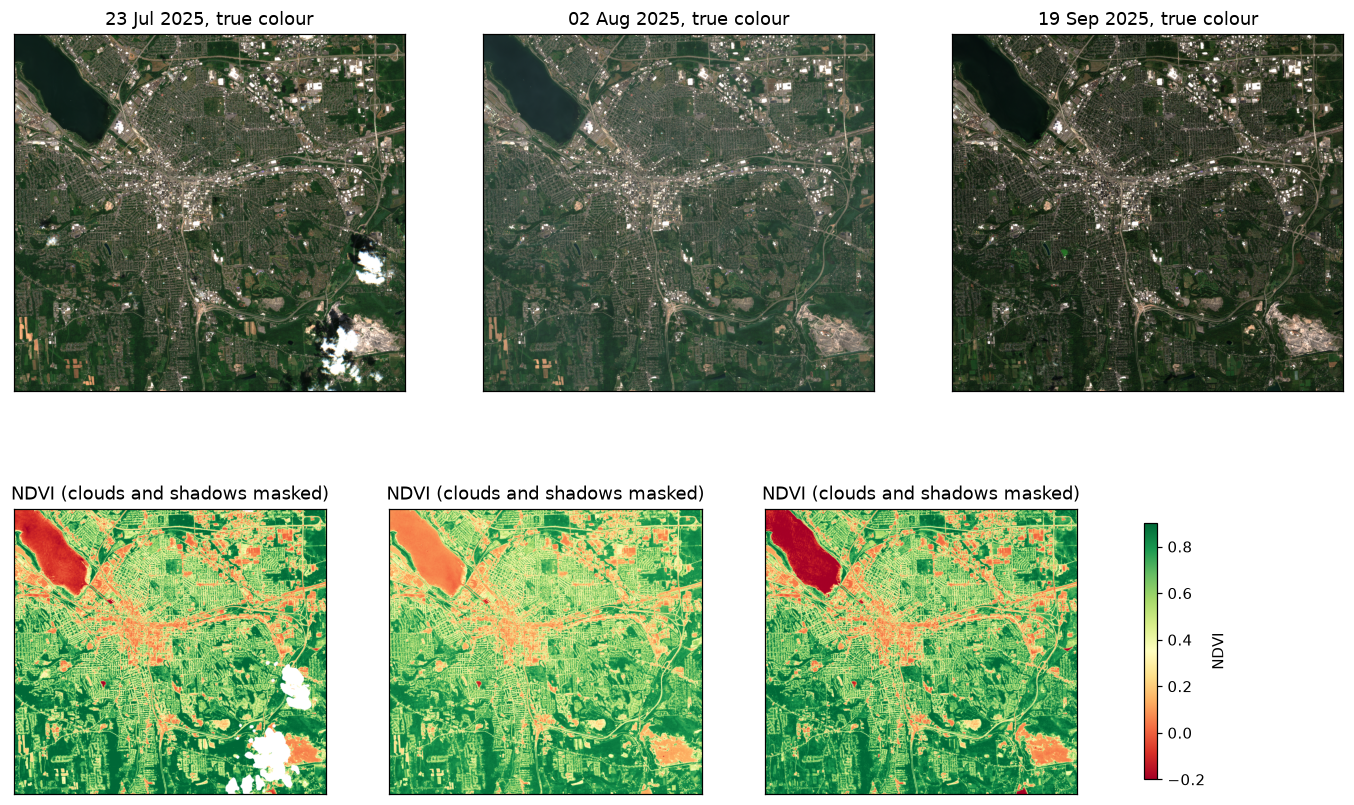

In [12]:
# Plot true-color RGB and masked NDVI for each date in the cube
fig, axes = plt.subplots(2, len(SCENES), figsize=(5.2 * len(SCENES), 9.5))
for j, t in enumerate(cube.time.values):
    s = cube.sel(time=t)
    rgb = np.stack([s.red, s.green, s.blue], -1)
    axes[0, j].imshow(np.clip(rgb / 0.25, 0, 1))
    axes[0, j].set_title(f"{pd.Timestamp(t):%d %b %Y}, true colour")
    im = axes[1, j].imshow(s.ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[1, j].set_title("NDVI (clouds and shadows masked)")
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=axes[1], shrink=0.7, label="NDVI")
plt.show()


After correct scaling the values are realistic: median red reflectance of 0.04-0.07 and median
NDVI of 0.61-0.66 for a city with dense tree cover. The scene classification marked 3.4% of the
23 July scene as cloud or shadow: the cumulus clouds in the south-east and their shadows, now
holes in the NDVI map. August and September were fully clear.

Onondaga Lake is negative in July (about −0.09) and September (about −0.2), but slightly positive
on 2 August (about +0.06). Water is normally negative, so on that date the lake was more
reflective in the NIR, which would fit greenish water (for example an algal bloom) or thin haze. A
single scene cannot tell which. Downtown, roads and the large bright site in the south-east stay
low in every scene.



## Zarr data cubes

GeoTIFF stores one raster per file; a **Zarr** store holds an n-dimensional array cut into
compressed **chunks**, one object per chunk, so a cube of any size can be read in parallel and
in pieces from disk or object storage. `rs.scale.to_zarr_cube` writes with spatial chunks and the
whole time axis together (good for time series) and can **append** new dates, the usual pattern
for monitoring.

In [13]:
# Persist the cube as Zarr in two appends, then verify contents and size
store = OUT / "syracuse_s2_2025.zarr"
if store.exists():
    shutil.rmtree(store)
zcube = cube[["red", "green", "blue", "nir", "ndvi"]]
rs.scale.to_zarr_cube(zcube.isel(time=slice(0, 2)), store, chunks={"x": 512, "y": 512})          # July and August
rs.scale.to_zarr_cube(zcube.isel(time=slice(2, 3)), store, append_dim="time")                     # September arrives later
z = rs.scale.open_cube(store)
print("Dimensions:", dict(z.sizes), "| NDVI chunks:", z.ndvi.data.chunksize, "| CRS:", z.rio.crs)
print("Identical to the in-memory cube:", bool(np.allclose(z.ndvi.values, zcube.ndvi.values, equal_nan=True)))

# Compare Zarr store size to the original band GeoTIFFs
objects = [p for p in store.rglob("*") if p.is_file()]
zarr_mb = sum(p.stat().st_size for p in objects) / 1e6
tif_mb = sum((S2_DIR / sid / f"{b}.tif").stat().st_size for sid in SCENES for b in BANDS) / 1e6
print(f"Zarr store: {len(objects)} objects, {zarr_mb:.1f} MB (four bands + NDVI); "
      f"the 12 downloaded band GeoTIFFs: {tif_mb:.1f} MB")


Dimensions: {'time': 3, 'y': 1354, 'x': 1485} | NDVI chunks: (2, 512, 512) | CRS: EPSG:32618
Identical to the in-memory cube: True
Zarr store: 104 objects, 76.0 MB (four bands + NDVI); the 12 downloaded band GeoTIFFs: 36.0 MB


In [14]:
# Lazily sample NDVI time series at a few lon/lat points from the Zarr cube
from pyproj import Transformer
to_utm = Transformer.from_crs(4326, z.rio.crs, always_xy=True)
points = {"Onondaga Lake": (-76.200, 43.080), "Downtown Syracuse": (-76.150, 43.048),
          "Residential south side": (-76.165, 43.031)}
t0 = time.perf_counter()
series = {name: z.ndvi.sel(x=to_utm.transform(*ll)[0], y=to_utm.transform(*ll)[1], method="nearest").load().to_series()
          for name, ll in points.items()}
print(f"Three pixel time series read lazily in {time.perf_counter() - t0:.2f} s")
pd.DataFrame(series).round(3)


Three pixel time series read lazily in 0.03 s


,Onondaga Lake,Downtown Syracuse,Residential south side
time,,,
2025-07-23 16:01:45.187,-0.086,0.114,0.725
2025-08-02 16:01:42.845,0.062,0.124,0.712
2025-09-19 16:11:16.421,-0.197,0.038,0.528


The Zarr store holds the three dates in 104 chunk objects. Appending September extended the time
axis without rewriting July and August, and the store reads back identical values. The NDVI chunks
are 2 × 512 × 512: the time chunk comes from the first write, which held two dates. Pixel time
series were read lazily in a few hundredths of a second, because each touches only one spatial
chunk.

The store (76 MB) is larger than the 12 downloaded band files (36 MB) because we stored float32
reflectance and NDVI rather than 16-bit integers. Storing the integers with their scale factor
would roughly halve it, which is the usual practice for large cubes.

The three points show the expected contrasts:

* Onondaga Lake: about −0.09, +0.06, −0.20.
* Downtown: about 0.11, 0.12, 0.04.
* A tree-lined residential area: about 0.72 in July and August, falling to 0.53 by 19 September.



## Publishing with STAC and GeoParquet

Products need a catalogue so others can find them. We write one NDVI COG per date and describe
them with `rs.scale.export_stac`, which records each file's footprint, date, projection and our
own properties. The item footprints also go into a GeoParquet table, a compact index that can be
filtered by bounding box without opening the catalogue (the idea behind *stac-geoparquet*).

In [15]:
# Write per-date NDVI COGs and export a small STAC catalog for them
ndvi_files, dates = [], []
for t in cube.time.values:
    when = pd.Timestamp(t)
    path = OUT / f"ndvi_syracuse_{when:%Y%m%d}.tif"
    rs.write(cube.ndvi.sel(time=t).rio.write_crs(cube.rio.crs).rio.write_nodata(np.nan), path)
    ndvi_files.append(path); dates.append(when.tz_localize("UTC").to_pydatetime())
print("All NDVI products are valid COGs:", all(web.validate_cog(p).valid for p in ndvi_files))

# Build a STAC catalog pointing at the NDVI assets
catalog_dir = OUT / "stac"
if catalog_dir.exists():
    shutil.rmtree(catalog_dir)
cat_path = rs.scale.export_stac(ndvi_files, catalog_dir, collection_id="syracuse-ndvi-2025",
                                description="Cloud-masked Sentinel-2 NDVI, Syracuse NY, summer 2025",
                                datetimes=dates, properties={"platform": "sentinel-2", "product": "NDVI",
                                                             "source_collection": "sentinel-2-l2a"})
# Imports and configuration
import pystac
catalog = pystac.Catalog.from_file(str(cat_path))
items = list(next(catalog.get_children()).get_items())
pd.DataFrame([{"id": it.id, "datetime": it.datetime, "bbox": np.round(it.bbox, 3).tolist(),
               "proj": it.properties.get("proj:code") or it.properties.get("proj:epsg"),
               "asset": Path(it.assets["data"].get_absolute_href()).name} for it in items])


All NDVI products are valid COGs: True


,id,datetime,bbox,proj,asset
0,ndvi_syracuse_20250723,2025-07-23 16:01:45.187000+00:00,"[-76.222, 42.978, -76.038, 43.102]",EPSG:32618,ndvi_syracuse_20250723.tif
1,ndvi_syracuse_20250802,2025-08-02 16:01:42.845000+00:00,"[-76.222, 42.978, -76.038, 43.102]",EPSG:32618,ndvi_syracuse_20250802.tif
2,ndvi_syracuse_20250919,2025-09-19 16:11:16.421000+00:00,"[-76.222, 42.978, -76.038, 43.102]",EPSG:32618,ndvi_syracuse_20250919.tif


In [16]:
# Index STAC items in GeoParquet, then bbox-query downtown Syracuse NDVI
index = gpd.GeoDataFrame(
    [{"id": it.id, "datetime": pd.Timestamp(it.datetime), "product": it.properties["product"],
      "href": it.assets["data"].get_absolute_href()} for it in items],
    geometry=[__import__("shapely.geometry", fromlist=["shape"]).shape(it.geometry) for it in items], crs=4326)
index_path = write_geoparquet(OUT / "syracuse_ndvi_items.parquet", index)
print(web.geoparquet_info(index_path)["num_rows"], "items indexed in", Path(index_path).name)

# Spatial filter the index and summarize August NDVI downtown
downtown = (-76.16, 43.04, -76.14, 43.06)
hits = read_geoparquet(index_path, bbox=downtown)
august = hits[hits["datetime"].dt.month == 8]
print("Items over downtown:", len(hits), "| in August:", list(august["id"]))
ndvi_aug = rs.read(august["href"].iloc[0]).squeeze("band", drop=True)
# Imports and configuration
from pyproj import Transformer
b = Transformer.from_crs(4326, ndvi_aug.rio.crs, always_xy=True).transform_bounds(*downtown)
print(f"Mean August NDVI over downtown: {float(ndvi_aug.rio.clip_box(*b).mean()):.3f}")


3 items indexed in syracuse_ndvi_items.parquet
Items over downtown: 3 | in August: ['ndvi_syracuse_20250802']
Mean August NDVI over downtown: 0.292


Each NDVI product is a valid COG. The STAC catalogue records every item's footprint, date and
projection (EPSG:32618), and links to its file. The GeoParquet index answers a footprint and date
query (items over downtown in August) without opening the catalogue, then the matching COG is
read: the mean August NDVI over a 2 × 2 km downtown box is 0.29, a mix of buildings, streets and
street trees.

The same pattern scales to thousands of products: a STAC API or a stac-geoparquet table for
discovery, and COGs or Zarr for the data.



## Summary and exercises

**Key ideas**

- `get_images` downloads clipped scenes with their STAC items; the item carries the scale,
  offset and no-data needed to use the pixels correctly.
- A COG is tiled, has internal overviews, and keeps headers first and pixels ordered from coarse
  to fine; `validate_cog` checks each rule and `to_cog` produces it.
- Lossless DEFLATE or ZSTD with a predictor is a good default; web-optimized COGs align with the
  XYZ tile grid.
- Zarr stores n-dimensional cubes as chunked objects and supports appending new dates.
- STAC describes products for discovery; a GeoParquet index of the footprints makes searches fast.

**What we found**

- `get_images` downloaded three clipped Sentinel-2 scenes (72 MB). The clips are tiled but are not
  COGs; `to_cog` fixed that.
- ZSTD or DEFLATE with a predictor made the smallest lossless COGs (14.9-15.9 MB from 16.1 MB of
  pixels plus two overview levels).
- A remote re-read of the same window from AWS was pixel-identical to the download.
- Earth Search has already removed Sentinel-2's +1,000 offset (Planetary Computer has not), even
  though its item still lists it. Getting this wrong makes reflectance negative.
- The Zarr cube appended a new date without rewriting, and a STAC catalogue with a GeoParquet index
  made the NDVI products searchable.

**Exercises**

1. Recompress the stack with `blocksize=256` and compare file size and the number of tiles a
   512 × 512 window touches.
2. Add `compress="LERC"` (lossy with a maximum error) or `"WEBP"` on an 8-bit RGB copy, and
   measure the size and the largest pixel error.
3. Use `search_images` to add the clearest 18TVN scene of October 2025, download it with
   `get_images`, and append it to the Zarr cube.
4. Write the NDVI cube to Zarr with chunks of `{"time": 1, "x": 256, "y": 256}` and time reading
   one full map versus one pixel's time series. Which chunking suits which question?
5. Open the STAC catalogue in another tool (QGIS's STAC browser or `pystac-client`) and check
   that the assets resolve.

**References**

- Cloud-Optimized GeoTIFF specification (OGC 21-026). https://docs.ogc.org/is/21-026/21-026.html
- GDAL COG driver documentation. https://gdal.org/drivers/raster/cog.html
- Zarr specification v2/v3. https://zarr.dev
- STAC specification and best practices. https://stacspec.org
- Cloud-Native Geospatial Foundation. *Cloud-Optimized Geospatial Formats Guide*. https://guide.cloudnativegeo.org